# Pipeline de análise de imagens de RX normal, pneumonia ou COVID19 visando emissão de laudos / diagnóstico automatizados a serem confirmados pelo profissional de medicina

### Rede Neural Xception

In [1]:
import pandas as pd
import numpy as np
import os
import shutil
import matplotlib.pyplot as plt
import math
import tensorflow as tf
import datetime
import keras
from keras import models
from keras import layers
from keras import optimizers
from keras.models import Sequential
from keras.layers import Dense, Conv2D , SeparableConv2D, MaxPool2D , Flatten , Dropout , BatchNormalization, Activation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img
from keras.callbacks import ReduceLROnPlateau
from keras import backend as K
from keras import optimizers
from sklearn.metrics import classification_report, recall_score, precision_score, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split

In [2]:
df = pd.DataFrame(columns=['class', 'directory'])

for path, names, filenames in os.walk('dataset/NORMAL/'):
    for filename in filenames:
        df.loc[len(df)] = ["NORMAL", 'NORMAL/' + filename]

for path, names, filenames in os.walk('dataset/COVID/'):
    for filename in filenames:
        df.loc[len(df)] = ["COVID", 'COVID/' + filename]

for path, names, filenames in os.walk('dataset/PNEUMONIA/'):
    for filename in filenames:
        df.loc[len(df)] = ["PNEUMONIA", 'PNEUMONIA/' + filename]

In [3]:
df

,class,directory
0,NORMAL,NORMAL/NORMAL.png
1,NORMAL,NORMAL/NORMAL_10.png
2,NORMAL,NORMAL/NORMAL_100.png
3,NORMAL,NORMAL/NORMAL_1000.png
4,NORMAL,NORMAL/NORMAL_1001.png
...,...,...
5223,PNEUMONIA,PNEUMONIA/PNEUMONIA_995.png
5224,PNEUMONIA,PNEUMONIA/PNEUMONIA_996.png
5225,PNEUMONIA,PNEUMONIA/PNEUMONIA_997.png
5226,PNEUMONIA,PNEUMONIA/PNEUMONIA_998.png


In [4]:
df_y = df['class']
df_x = df['directory']

In [5]:
df_x

0                 NORMAL/NORMAL.png
1              NORMAL/NORMAL_10.png
2             NORMAL/NORMAL_100.png
3            NORMAL/NORMAL_1000.png
4            NORMAL/NORMAL_1001.png
                   ...             
5223    PNEUMONIA/PNEUMONIA_995.png
5224    PNEUMONIA/PNEUMONIA_996.png
5225    PNEUMONIA/PNEUMONIA_997.png
5226    PNEUMONIA/PNEUMONIA_998.png
5227    PNEUMONIA/PNEUMONIA_999.png
Name: directory, Length: 5228, dtype: str

In [6]:
df_y.value_counts()

class
NORMAL       1802
PNEUMONIA    1800
COVID        1626
Name: count, dtype: int64

In [7]:
X_train, X_test, y_train, y_test = train_test_split(df_x, df_y, stratify= df_y, test_size=0.20, random_state=42)

In [8]:
y_train.value_counts()

class
NORMAL       1441
PNEUMONIA    1440
COVID        1301
Name: count, dtype: int64

In [9]:
test = pd.concat([X_test, y_test], axis = 1)
test.head()

,directory,class
4737,PNEUMONIA/PNEUMONIA_557.png,PNEUMONIA
4274,PNEUMONIA/PNEUMONIA_1760.png,PNEUMONIA
1375,NORMAL/NORMAL_614.png,NORMAL
3127,COVID/COVID_728.png,COVID
3584,PNEUMONIA/PNEUMONIA_1139.png,PNEUMONIA


In [10]:
train = pd.concat([X_train, y_train], axis = 1)
train.head()

,directory,class
4932,PNEUMONIA/PNEUMONIA_732.png,PNEUMONIA
5164,PNEUMONIA/PNEUMONIA_941.png,PNEUMONIA
1632,NORMAL/NORMAL_846.png,NORMAL
3928,PNEUMONIA/PNEUMONIA_1449.png,PNEUMONIA
4805,PNEUMONIA/PNEUMONIA_618.png,PNEUMONIA


In [11]:
def copy_images(df, directory):
    input_path = 'dataset'
    output_path = "./out/" + directory

    # Se algum arquivo antigo existe no path de saída, ele é removido
    if os.path.exists(output_path):
        shutil.rmtree(output_path)

    # Criando a pasta dentro do path de saída
    if not os.path.exists(output_path):
        os.makedirs(output_path)

    # Criando três subpastas
    classes = ['NORMAL', 'COVID', 'PNEUMONIA']
    for c in classes:
        if not os.path.exists(output_path + '/' + c):
            os.makedirs(output_path + '/' + c)

   # O dataframe original contém um diretório para cada linha, esses diretórios são deslocados do diretório de entrada para o diretório de saída
    for i, row in df.iterrows():
        path_from = "{}/{}".format(input_path, row['directory'])
        path_to = "{}/{}".format(output_path, row['directory'])
        shutil.copy(path_from, path_to)

In [12]:
# Move as imagens de teste e de treino do diretório de entrada para o diretório de saída
copy_images(test, 'test')
copy_images(train, 'train')

In [13]:
print(len(os.listdir('./out/train/NORMAL')))
print(len(os.listdir('./out/train/COVID')))
print(len(os.listdir('./out/train/PNEUMONIA')))

1441
1301
1440


In [14]:
print(len(os.listdir('./out/test/NORMAL')))
print(len(os.listdir('./out/test/COVID')))
print(len(os.listdir('./out/test/PNEUMONIA')))

361
325
360


In [15]:
# Treinando os dados
train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        zoom_range=0.4,
        horizontal_flip=True,
        validation_split=0.01
        )


class_order = ['NORMAL', 'COVID', 'PNEUMONIA']

train_generator = train_datagen.flow_from_directory(
    './out/train',
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    classes=class_order,
    subset='training'
)

Found 4141 images belonging to 3 classes.


In [16]:
# Validando os dados
val_generator = train_datagen.flow_from_directory(
    './out/train',
    target_size=(100, 100),
    batch_size=32,
    class_mode='categorical',
    classes=class_order,
    subset='validation'
)

Found 41 images belonging to 3 classes.


In [17]:
# Testando os dados
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    './out/test',
    target_size=(100, 100),
    batch_size=32,
    class_mode='categorical',
    classes=class_order,
    shuffle=False
)

Found 1046 images belonging to 3 classes.


In [18]:
# Aplicando o modelo Xception pré-treinado
xception=tf.keras.applications.Xception(input_shape=(100,100,3),
                             include_top=False,
                             weights='imagenet')

# Congelando as camadas (layers)
for layer in xception.layers:
    layer.trainable=False

In [19]:
last_layer=xception.layers[-1]
last_output = last_layer.output

In [20]:
x=layers.Flatten()(last_output)

# Adicionando uma camada extra
x=layers.Dense(256,activation='relu')(x)

# Camada de saída
x=layers.Dense(3,activation='softmax')(x)

xception_model=keras.Model(xception.input,x)

In [21]:
xception_model.compile(optimizer='adam',
              loss='categorical_crossentropy',
               metrics=['accuracy'])

In [22]:
xception_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 49, 49,    │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 49, 49,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 49, 49,    │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 47, 47,    │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 47, 47,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 47, 47,    │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 47, 47,    │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 47, 47,    │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 47, 47,    │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 47, 47,    │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 47, 47,    │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 24, 24,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 24, 24,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 24, 24,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 24,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 24, 24,    │          0 │ add[0][0]       

 Total params: 25,581,099 (97.58 MB)

 Trainable params: 4,719,619 (18.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)



In [23]:
keras.utils.plot_model(xception_model)

In [24]:
history_xception = xception_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

Epoch 1/5
130/130 ━━━━━━━━━━━━━━━━━━━━ 108s 790ms/step - accuracy: 0.8054 - loss: 0.9699 - val_accuracy: 0.8049 - val_loss: 0.8059
Epoch 2/5
130/130 ━━━━━━━━━━━━━━━━━━━━ 53s 410ms/step - accuracy: 0.8556 - loss: 0.4820 - val_accuracy: 0.8537 - val_loss: 0.4325
Epoch 3/5
130/130 ━━━━━━━━━━━━━━━━━━━━ 54s 412ms/step - accuracy: 0.8703 - loss: 0.3526 - val_accuracy: 0.9756 - val_loss: 0.1424
Epoch 4/5
130/130 ━━━━━━━━━━━━━━━━━━━━ 52s 400ms/step - accuracy: 0.8848 - loss: 0.3204 - val_accuracy: 0.8537 - val_loss: 0.4580
Epoch 5/5
130/130 ━━━━━━━━━━━━━━━━━━━━ 51s 394ms/step - accuracy: 0.8858 - loss: 0.3048 - val_accuracy: 0.9268 - val_loss: 0.3036


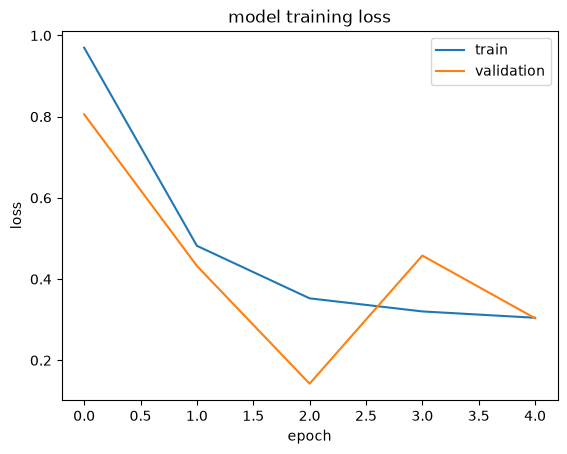

In [25]:
plt.plot(history_xception.history['loss'])
plt.plot(history_xception.history['val_loss'])
plt.title('model training loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

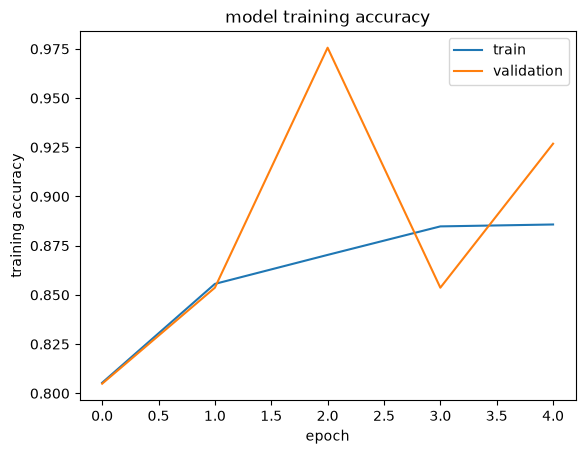

In [26]:
plt.plot(history_xception.history['accuracy'])
plt.plot(history_xception.history['val_accuracy'])
plt.title('model training accuracy')
plt.ylabel('training accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [27]:
# Avaliando os dados do teste
x = xception_model.evaluate(test_generator)

33/33 ━━━━━━━━━━━━━━━━━━━━ 19s 578ms/step - accuracy: 0.8843 - loss: 0.3225


In [28]:
print(f'Testing loss: {x[0]}')
print(f'Testing accuracy: {x[1]}')

Testing loss: 0.3224773108959198
Testing accuracy: 0.8843212127685547


33/33 ━━━━━━━━━━━━━━━━━━━━ 13s 352ms/step
Mapeamento das classes:
{'NORMAL': 0, 'COVID': 1, 'PNEUMONIA': 2}

Relatório de classificação:
              precision    recall  f1-score   support

      Normal       0.78      0.97      0.87       361
       Covid       0.98      0.95      0.97       325
   Pneumonia       0.94      0.74      0.83       360

    accuracy                           0.88      1046
   macro avg       0.90      0.89      0.89      1046
weighted avg       0.90      0.88      0.88      1046

Accuracy: 0.8843

Matriz de confusão:
[[350   2   9]
 [  7 310   8]
 [ 90   5 265]]


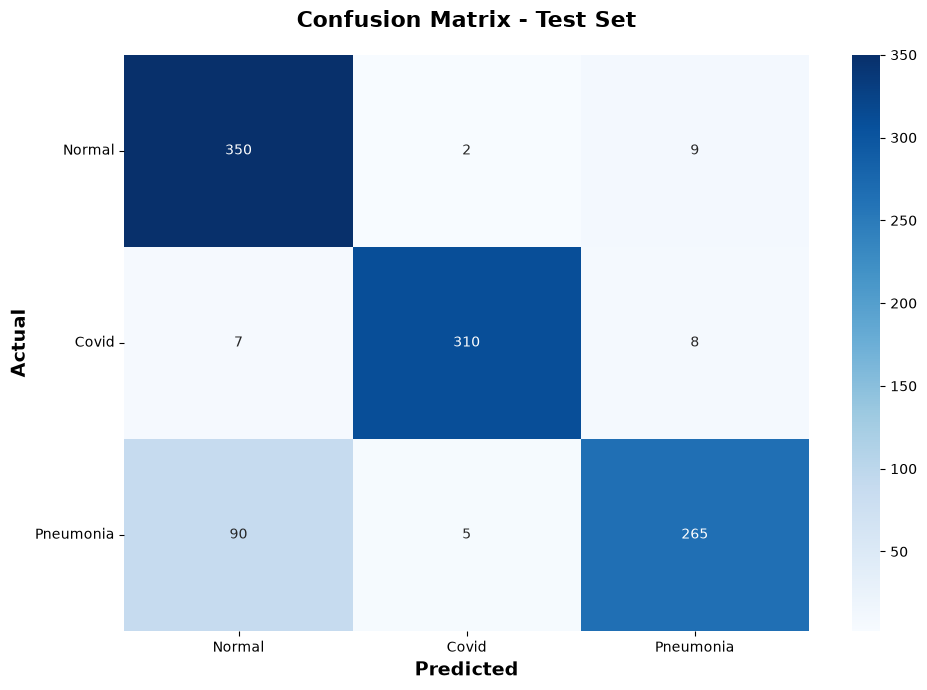

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Reinicia o gerador para garantir a ordem correta
test_generator.reset()

# Faz as previsões
y_hat = xception_model.predict(test_generator)

# Converte as probabilidades em classes
y_predictions = np.argmax(y_hat, axis=1)

# Classes verdadeiras
y_true = test_generator.classes

# Ordem padronizada das classes
class_names = ['Normal', 'Covid', 'Pneumonia']

print("Mapeamento das classes:")
print(test_generator.class_indices)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_true,
        y_predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        digits=2
    )
)

accuracy = accuracy_score(y_true, y_predictions)
print(f"Accuracy: {accuracy:.4f}")

# Matriz de confusão
cm = confusion_matrix(
    y_true,
    y_predictions,
    labels=[0, 1, 2]
)

print("\nMatriz de confusão:")
print(cm)

plt.figure(figsize=(10, 7))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

ax.set_xlabel('Predicted', fontsize=14, fontweight='bold')
ax.set_ylabel('Actual', fontsize=14, fontweight='bold')
ax.set_title(
    'Confusion Matrix - Test Set',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()